Predict future averge price of Oil and Fats monthly in Yangon by using SARIMAX model and Linear Regression Model
* According to the result, Linear Regression is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2009-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2010-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DOFM_Y = data.copy()
mask = (DOFM_Y['category']=='oil and fats') & (DOFM_Y['region']=='Yangon')
DOFM_Y = DOFM_Y[mask]
DOFM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1100,1/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,3087.34,1.7345
1203,2/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2973.68,1.6706
1314,3/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2910.92,1.6353
1420,4/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2858.37,1.6058
1530,5/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2912.63,1.6363


In [13]:
DOFM_Y = DOFM_Y[['date', 'price']]
DOFM_Y['date'] = pd.to_datetime(DOFM_Y['date'])
mask = (DOFM_Y['date']>=obv_st_date) & (DOFM_Y['date']<=obv_end_date)
DOFM_Y = DOFM_Y.loc[mask]
DOFM_Y = DOFM_Y.set_index('date')
DOFM_Y.head()

,price
date,
2009-01-15,3087.34
2009-02-15,2973.68
2009-03-15,2910.92
2009-04-15,2858.37
2009-05-15,2912.63


In [14]:
DOFM_Y = DOFM_Y.resample('MS').mean()
DOFM_Y.head()

,price
date,
2009-01-01,3087.34
2009-02-01,2973.68
2009-03-01,2910.92
2009-04-01,2858.37
2009-05-01,2912.63


In [15]:
price = DOFM_Y['price']
date = DOFM_Y.index

##### Normalization data

In [16]:
scaler = MinMaxScaler()

In [17]:
DOFM_Y_nor = scaler.fit_transform(DOFM_Y)
DOFM_Y_nor = pd.DataFrame(DOFM_Y_nor)
DOFM_Y_nor.head()

,0
0,0.235625
1,0.197710
2,0.176774
3,0.159244
4,0.177344


In [18]:
DOFM_Y_nor['date']=date
DOFM_Y_nor = DOFM_Y_nor.set_index('date')
DOFM_Y_nor.columns=['price']
DOFM_Y_nor.head()

,price
date,
2009-01-01,0.235625
2009-02-01,0.197710
2009-03-01,0.176774
2009-04-01,0.159244
2009-05-01,0.177344


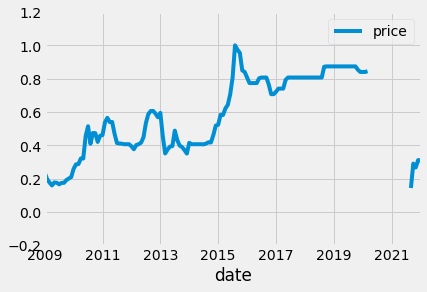

In [19]:
DOFM_Y_nor.plot(grid=True)
plt.show()

In [20]:
DOFM_Y_nor = DOFM_Y_nor.interpolate(method="linear")
DOFM_Y_nor.shape

(157, 1)

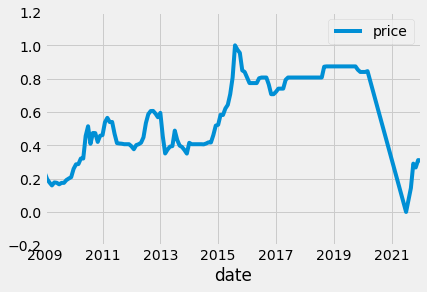

In [21]:
DOFM_Y_nor.plot(grid=True)
plt.show()

It has positive trend.

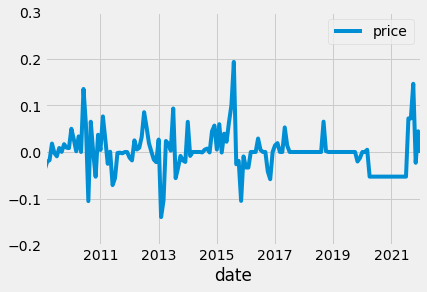

In [22]:
DOFM_Y_nor_diff1 = DOFM_Y_nor.diff(1).dropna()
DOFM_Y_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [23]:
RW_DOFM_Y= adfuller(DOFM_Y_nor_diff1)
RW_DOFM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

2.228652455198949e-14

##### Plotting ACF and PACF

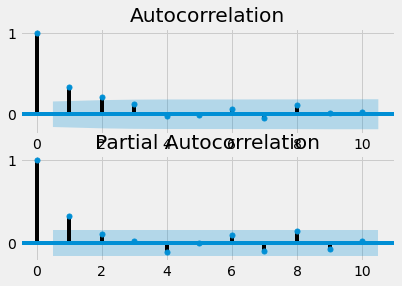

In [24]:
fig, axes=plt.subplots(2,1)
plot_acf(DOFM_Y_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DOFM_Y_nor_diff1, lags=10, ax=axes[1])
plt.show()

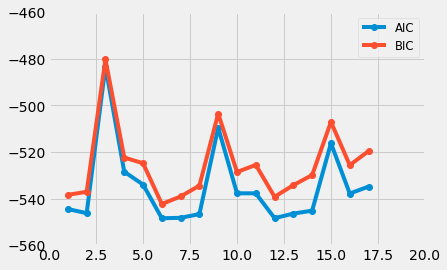

In [25]:
AIC, BIC = AIC_BIC_withOrderRange(DOFM_Y_nor_diff1, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [26]:
AIC, BIC

(array([-532.28083137, -544.46512599, -546.21827077, -483.37014008,
        -528.46493376, -533.95570915, -548.40045943, -548.22320979,
        -546.61232772, -509.61307504, -537.70740001, -537.72354421,
        -548.35947092, -546.41193239, -545.13626431, -516.23590347,
        -537.80971222, -534.8321298 ]),
 array([-529.23097536, -538.36541398, -537.06870275, -480.32671496,
        -522.37808353, -524.8254338 , -542.30074741, -539.07364177,
        -534.41290369, -503.52622481, -528.57712466, -525.54984374,
        -539.2099029 , -534.21250836, -529.88698428, -507.10562812,
        -525.63601175, -519.61500421]))

We will run again 1:(0,0,1), 2:(0,0,2), 6:(1,0,0), 12:(2,0,0)

In [27]:
mod_orders = [
    (0,0,1), 
    (0,0,2), 
    (1,0,0), 
    (2,0,0), 
]

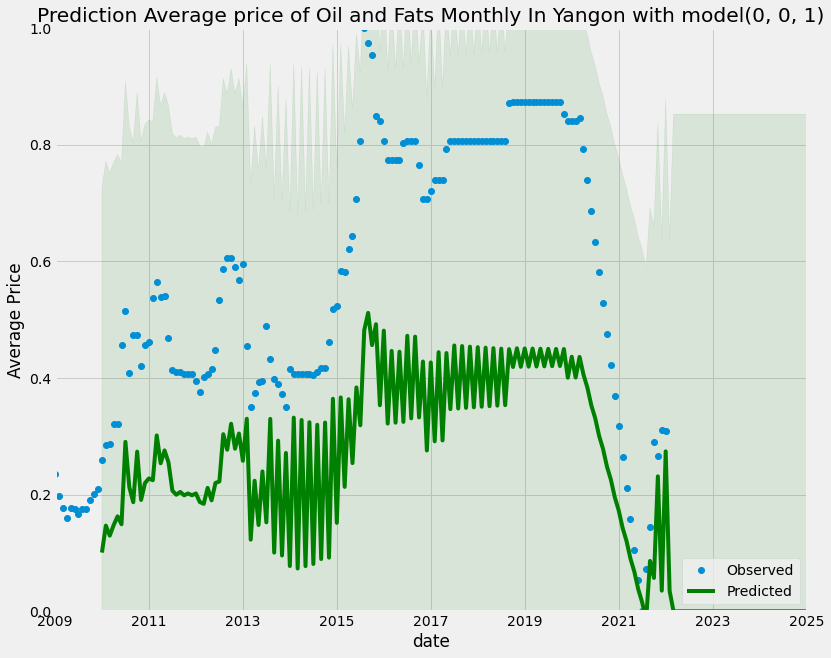

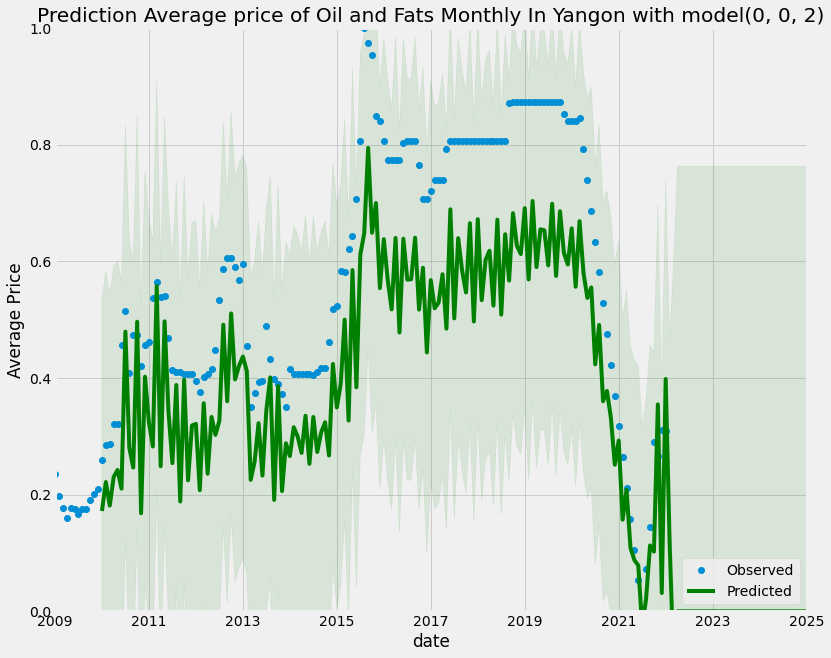

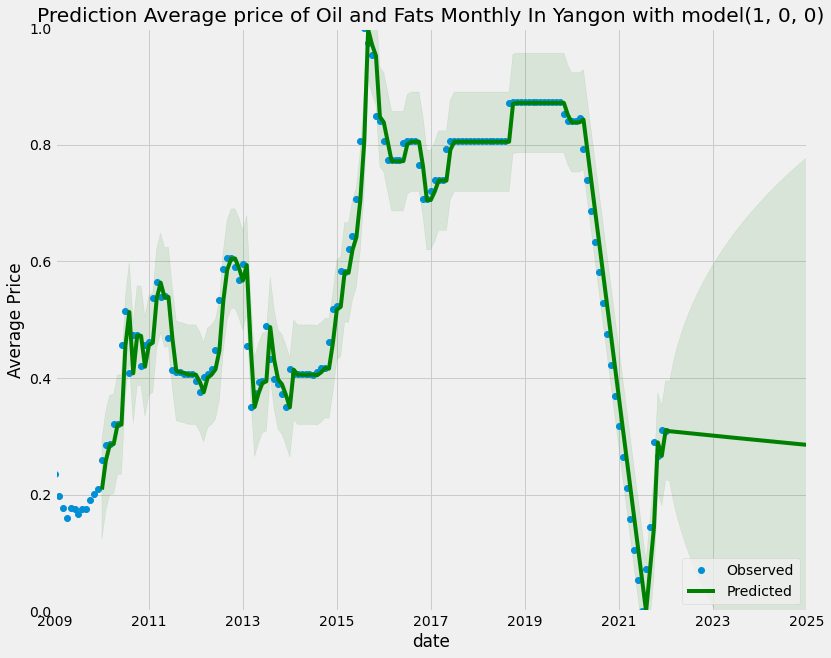

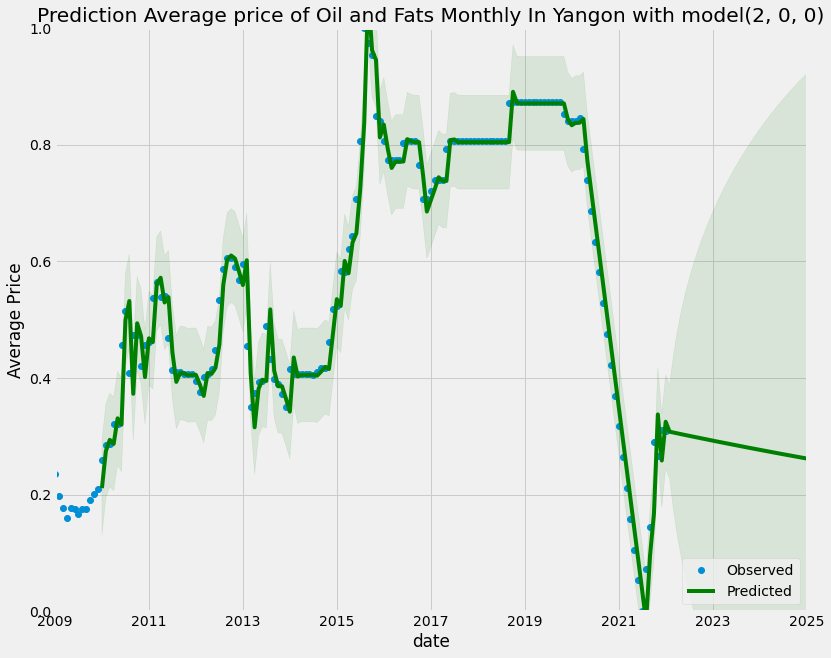

In [28]:
DOFM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DOFM_Y_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Oil and Fats Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DOFM_Y_models.append(model)

Now we choose (0,1,0)

In [29]:
DOFM_Y_model = DOFM_Y_models[2]

In [30]:
DOFM_Y_pred_normalized = DOFM_Y_model.predict(pred_st_date, pred_end_date)
DOFM_Y_pred_normalized

2010-01-01    0.208675
2010-02-01    0.258308
2010-03-01    0.285294
2010-04-01    0.286825
2010-05-01    0.320139
                ...   
2024-09-01    0.288021
2024-10-01    0.287375
2024-11-01    0.286729
2024-12-01    0.286086
2025-01-01    0.285443
Freq: MS, Length: 181, dtype: float64

In [31]:
mask = (DOFM_Y_nor.index>=pred_st_date) & (DOFM_Y_nor.index<=pred_end_date)
DOFM_Y_pred = DOFM_Y_nor.loc[mask]
DOFM_Y_pred

,price
date,
2010-01-01,0.258889
2010-02-01,0.285936
2010-03-01,0.287471
2010-04-01,0.320859
2010-05-01,0.320859
...,...
2021-09-01,0.143958
2021-10-01,0.290153
2021-11-01,0.267014


We need to un-normalized the predicted value to get actual price

In [32]:
pred_date = DOFM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2010-01-01', '2010-02-01', '2010-03-01', '2010-04-01',
               '2010-05-01', '2010-06-01', '2010-07-01', '2010-08-01',
               '2010-09-01', '2010-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=180, freq='MS')

In [33]:
DOFM_Y_pred_normalized_df = pd.DataFrame(DOFM_Y_pred_normalized)
DOFM_Y_pred_normalized_df = DOFM_Y_pred_normalized_df[:-1] # the last index doesn't need
DOFM_Y_pred_normalized_df

,0
2010-01-01,0.208675
2010-02-01,0.258308
2010-03-01,0.285294
2010-04-01,0.286825
2010-05-01,0.320139
...,...
2024-08-01,0.288669
2024-09-01,0.288021
2024-10-01,0.287375
2024-11-01,0.286729


##### Un-normalization data

In [34]:
DOFM_Y_pred_act = scaler.inverse_transform(DOFM_Y_pred_normalized_df)
DOFM_Y_pred_act_df = pd.DataFrame(DOFM_Y_pred_act)
DOFM_Y_pred_act_df['date'] = pred_date
DOFM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DOFM_Y_pred_act_df.set_index('date',  inplace=True)
DOFM_Y_pred_act_df

,Predicted Price
date,
2010-01-01,3006.552357
2010-02-01,3155.337555
2010-03-01,3236.235515
2010-04-01,3240.825187
2010-05-01,3340.690466
...,...
2024-08-01,3246.352660
2024-09-01,3244.409781
2024-10-01,3242.471264


In [35]:
mask = (DOFM_Y.index>=pred_st_date) & (DOFM_Y.index<=pred_end_date)
DOFM_Y_Act = DOFM_Y.loc[mask]
DOFM_Y_Act

,price
date,
2010-01-01,3157.0800
2010-02-01,3238.1600
2010-03-01,3242.7600
2010-04-01,3342.8500
2010-05-01,3342.8500
...,...
2021-09-01,2812.5475
2021-10-01,3250.8000
2021-11-01,3181.4360


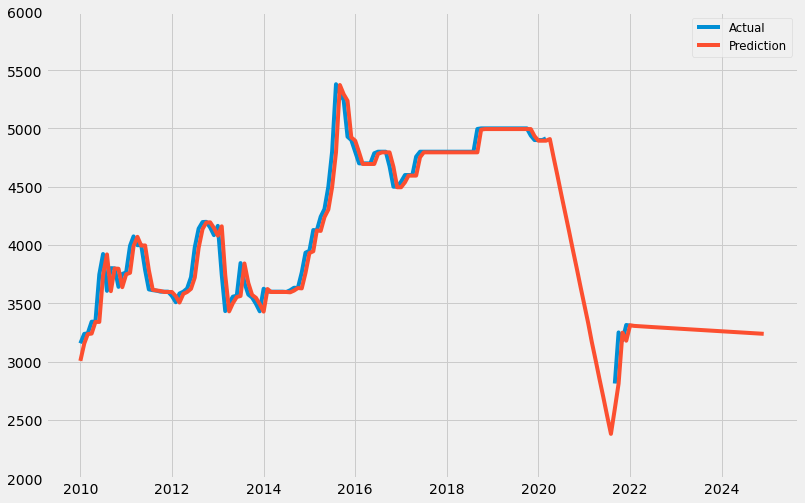

In [36]:
plt.figure(figsize=(12,8))
plt.plot(DOFM_Y_Act, label="Actual")
plt.plot(DOFM_Y_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [37]:
temp_df = DOFM_Y_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2009-01-01,0.235625
1,2009-02-01,0.197710
2,2009-03-01,0.176774
3,2009-04-01,0.159244
4,2009-05-01,0.177344
...,...,...
152,2021-09-01,0.143958
153,2021-10-01,0.290153
154,2021-11-01,0.267014
155,2021-12-01,0.311361


In [38]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2009-01-01  0.235625  1230768000000000000
 2   2009-03-01  0.176774  1235865600000000000
 3   2009-04-01  0.159244  1238544000000000000
 4   2009-05-01  0.177344  1241136000000000000
 5   2009-06-01  0.175219  1243814400000000000
 ..         ...       ...                  ...
 152 2021-09-01  0.143958  1630454400000000000
 153 2021-10-01  0.290153  1633046400000000000
 154 2021-11-01  0.267014  1635724800000000000
 155 2021-12-01  0.311361  1638316800000000000
 156 2022-01-01  0.309501  1640995200000000000
 
 [130 rows x 3 columns],
           date     price                 time
 1   2009-02-01  0.197710  1233446400000000000
 10  2009-11-01  0.200859  1257033600000000000
 13  2010-02-01  0.285936  1264982400000000000
 17  2010-06-01  0.455948  1275350400000000000
 21  2010-10-01  0.473358  1285891200000000000
 24  2011-01-01  0.461623  1293840000000000000
 26  2011-03-01  0.564774  1298937600000000000
 30  2011-07-01  0.413096  130947

In [39]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1230768000000000000],
        [1235865600000000000],
        [1238544000000000000],
        [1241136000000000000],
        [1243814400000000000],
        [1246406400000000000],
        [1249084800000000000],
        [1251763200000000000],
        [1254355200000000000],
        [1259625600000000000]], dtype=int64),
 array([0.23562496, 0.17677376, 0.15924383, 0.17734419, 0.17521925,
        0.16598226, 0.17456209, 0.17474556, 0.19154827, 0.20914492]))

In [40]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1233446400000000000],
        [1257033600000000000],
        [1264982400000000000],
        [1275350400000000000],
        [1285891200000000000],
        [1293840000000000000],
        [1298937600000000000],
        [1309478400000000000],
        [1335830400000000000],
        [1375315200000000000]], dtype=int64),
 array([0.1977096 , 0.20085865, 0.28593636, 0.45594833, 0.47335817,
        0.46162263, 0.56477401, 0.41309591, 0.41571789, 0.43237383]))

In [41]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [42]:
DOFM_Y_linreg = LinearRegression().fit(X_train, y_train)

In [43]:
print('linear model coeff or slope (w): {}'.format(DOFM_Y_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DOFM_Y_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DOFM_Y_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DOFM_Y_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [8.37410456e-19]
linear model intercept (b): -0.646
R-squared score (training): 0.169
R-squared score (test): 0.131


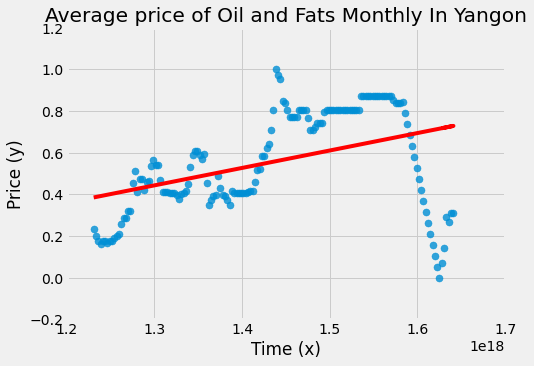

In [44]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DOFM_Y_linreg.coef_ * X + DOFM_Y_linreg.intercept_, 'r-')
plt.title('Average price of Oil and Fats Monthly In Yangon')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [45]:
DOFM_Y_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DOFM_Y_linear_predict['time'] = DOFM_Y_linear_predict['date'].apply(lambda x: x.value)
DOFM_Y_linear_predict

,date,time
0,2010-01-01,1262304000000000000
1,2010-02-01,1264982400000000000
2,2010-03-01,1267401600000000000
3,2010-04-01,1270080000000000000
4,2010-05-01,1272672000000000000
...,...,...
176,2024-09-01,1725148800000000000
177,2024-10-01,1727740800000000000
178,2024-11-01,1730419200000000000
179,2024-12-01,1733011200000000000


In [46]:
time_predict = np.array(DOFM_Y_linear_predict['time']).reshape((-1, 1))
DOFM_Y_linear_predict['price'] = DOFM_Y_linreg.predict(time_predict)
DOFM_Y_linear_predict

,date,time,price
0,2010-01-01,1262304000000000000,0.411428
1,2010-02-01,1264982400000000000,0.413671
2,2010-03-01,1267401600000000000,0.415697
3,2010-04-01,1270080000000000000,0.417940
4,2010-05-01,1272672000000000000,0.420110
...,...,...,...
176,2024-09-01,1725148800000000000,0.799019
177,2024-10-01,1727740800000000000,0.801190
178,2024-11-01,1730419200000000000,0.803433
179,2024-12-01,1733011200000000000,0.805603


In [47]:
DOFM_Y_linear_normalized_predict = DOFM_Y_linear_predict.copy()
DOFM_Y_linear_normalized_predict = DOFM_Y_linear_normalized_predict[['date', 'price']]
DOFM_Y_linear_normalized_predict.set_index('date', inplace=True)
DOFM_Y_linear_normalized_predict

,price
date,
2010-01-01,0.411428
2010-02-01,0.413671
2010-03-01,0.415697
2010-04-01,0.417940
2010-05-01,0.420110
...,...
2024-09-01,0.799019
2024-10-01,0.801190
2024-11-01,0.803433


##### Unnormalized the data

##### The Prediction Average Price of Oil and Fats Per KG using Linear Regression

In [48]:
DOFM_Y_pred_act_KG_linear_df = scaler.inverse_transform(DOFM_Y_linear_normalized_predict)
DOFM_Y_pred_act_KG_linear_df = pd.DataFrame(DOFM_Y_pred_act_KG_linear_df)
DOFM_Y_pred_act_KG_linear_df['date'] = DOFM_Y_linear_predict['date']
DOFM_Y_pred_act_KG_linear_df.columns = ['Predicted Price (KG)', 'date']
DOFM_Y_pred_act_KG_linear_df.set_index('date', inplace=True)
DOFM_Y_pred_act_KG_linear_df

,Predicted Price (KG)
date,
2010-01-01,3614.350171
2010-02-01,3621.073840
2010-03-01,3627.146832
2010-04-01,3633.870501
2010-05-01,3640.377277
...,...
2024-09-01,4776.243564
2024-10-01,4782.750341
2024-11-01,4789.474010


##### The Prediction Average Price of Oil and Fats Per Viss using Linear Regression

1 Viss = 1.63293 KG

In [49]:
DOFM_Y_pred_act_Viss_linear_df = DOFM_Y_pred_act_KG_linear_df.copy()
DOFM_Y_pred_act_Viss_linear_df.columns = ['Predicted Price (Viss)']
DOFM_Y_pred_act_Viss_linear_df['Predicted Price (Viss)'] = DOFM_Y_pred_act_Viss_linear_df['Predicted Price (Viss)'] * 1.63293
DOFM_Y_pred_act_Viss_linear_df

,Predicted Price (Viss)
date,
2010-01-01,5901.980825
2010-02-01,5912.960106
2010-03-01,5922.876876
2010-04-01,5933.856157
2010-05-01,5944.481267
...,...
2024-09-01,7799.271403
2024-10-01,7809.896514
2024-11-01,7820.875795
